# Run 0 — DiffWater (pretrained, no fine-tuning) on EUVP

**What Run 0 is:** apply the *pretrained* DiffWater model directly to our EUVP input images, with **no fine-tuning**, and save the outputs as the baseline.

**Model:** DiffWater — conditional DDPM for underwater enhancement (https://github.com/Guan-MS/DiffWater, Apache-2.0).
**Weights:** from the authors' Google Drive folder (trained on LSUI / UIEB / SQUID / U45, not EUVP).

**Runtime:** `Runtime > Change runtime type > T4 GPU`.

**How this notebook is organised**

| Step | What it does |
|---|---|
| 1 | Check the GPU |
| 2 | Clone the DiffWater code, install the few missing packages |
| 3 | Download the pretrained weights from Drive and pick the checkpoint |
| 4 | Build a small paired EUVP test folder in the layout DiffWater expects |
| 5 | Write a Run-0 config and verify the noise schedule (θₜ = ᾱₜ ∈ (0,1)) |
| 6 | Dry run: load the weights, count parameters, time one denoising step, estimate time per image |
| 7 | Run inference (seeded) |
| 8 | Compute PSNR/SSIM vs. the reference images and look at the outputs |
| 9 | Save everything to Drive |

> **Heads-up:** DiffWater samples with **all 2000 diffusion steps per image** (no step skipping). Step 6 tells you how long one image will take on *your* T4 before you commit to a bigger run. Start with `N_IMAGES = 5`.

## Step 1 — Check the GPU
We need a CUDA GPU. A T4 has ~15 GB of memory; this model runs inference at batch size 1 so memory should not be the limit (Step 6 measures it).

In [1]:
import sys, torch
!nvidia-smi --query-gpu=name,memory.total --format=csv
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU, then re-run."

name, memory.total [MiB]
Tesla T4, 15360 MiB
Python 3.13.16 | torch 2.11.0+cu130 | CUDA available: True


## Step 2 — Get the code and dependencies
The repo keeps its code in a *nested* `DiffWater/DiffWater/` folder, so we set `REPO_DIR` to that. We also print the git commit so the exact code version is on record (the assignment README needs this kind of detail).

Colab already has torch, numpy, opencv, pandas, tqdm and Pillow. We only add `tensorboardX` (imported by `test.py`), `scikit-image` (colour-channel compensation + our metrics), `lmdb`, `pyyaml`, `gdown`.

In [2]:
import os, subprocess

REPO_ROOT = "/content/DiffWater"
REPO_DIR = f"{REPO_ROOT}/DiffWater"      # the real code lives in the nested folder

if not os.path.isdir(REPO_ROOT):
    subprocess.run(["git", "clone", "-q", "https://github.com/Guan-MS/DiffWater.git", REPO_ROOT], check=True)

print("commit:", subprocess.run(["git", "-C", REPO_ROOT, "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip())
print(os.listdir(REPO_DIR))
!pip -q install tensorboardX scikit-image lmdb pyyaml gdown

commit: 7db68f34060bbf1d7c5b8153664fb16a3dcda1ae
['README.md', 'model', 'config', 'requirement.txt', 'test.py', 'core', 'eval.py', 'train.py', 'data']


## Step 3 — Download the pretrained weights
DiffWater's weights are in a public Google Drive folder:
https://drive.google.com/drive/folders/11T9ao0pmNFv9lVZLcVliNbZ3iJ5F2t7s

**Colab's local disk (`/content`) is wiped on every disconnect; your Google Drive is not.** So the weights are stored on *your Drive* and read from there. The first session downloads them once; every later session finds them and skips the download.

**What you actually need:** the shared folder has two models, `LSUI/` and `UIEB/`. Each holds `I…_gen.pth` (~593 MB for LSUI: the weights, **the only file Run 0 needs**) and `I…_opt.pth` (~1.16 GB of optimizer state, needed only to resume training). Downloading the whole shared folder would pull a few GB you don't need.

**Recommended route — copy just one file in the browser (3b below), then run 3a.** 3a notices the file is already on Drive and skips the download. The notebook expects it anywhere under `My Drive/DW`.

**3a — download / list.** It looks in `My Drive/DW` (and its subfolders, e.g. `DW/LSUI/`). If a `*_gen.pth` is already there, it does nothing. Otherwise it falls back to `gdown --folder` on the whole shared folder (slow, several GB, and may hit Drive's quota).

In [3]:
import glob
from google.colab import drive
drive.mount("/content/drive")

FOLDER_URL = "https://drive.google.com/drive/folders/11T9ao0pmNFv9lVZLcVliNbZ3iJ5F2t7s"
CKPT_DIR = "/content/drive/MyDrive/DW"   # on Drive: survives disconnects. Searched recursively, so DW/LSUI/... is found

if glob.glob(f"{CKPT_DIR}/**/*_gen.pth", recursive=True):
    print("checkpoint already on Drive - skipping download")
else:
    subprocess.run(["gdown", "--folder", FOLDER_URL, "-O", CKPT_DIR])

for p in sorted(glob.glob(f"{CKPT_DIR}/**/*", recursive=True)):
    if os.path.isfile(p):
        print(f"{os.path.getsize(p)/1e6:10.1f} MB  {p}")

Mounted at /content/drive
checkpoint already on Drive - skipping download
     621.5 MB  /content/drive/MyDrive/DW/LSUI/I390000_E78_gen.pth
     621.5 MB  /content/drive/MyDrive/DW/LSUI/I860000_E607_gen.pth


**3b — copy one file in the browser (recommended; do this before running 3a).** Open the Drive folder above → pick a model subfolder → right-click its `*_gen.pth` → *Make a copy*. (Drive cannot copy whole folders, only files, and you do not need the `_opt.pth`.) Keep the copy under `My Drive/DW` (the path 3a uses), or edit `CKPT_DIR` below. (A *shortcut* is not enough — it must be a real copy.) Colab then never has to download anything.

In [4]:
# Lists what is in the Drive folder after you copied the file in the browser (also use this if 3a failed).
CKPT_DIR = "/content/drive/MyDrive/DW"   # <-- edit if you put the copy elsewhere
for p in sorted(glob.glob(f"{CKPT_DIR}/**/*", recursive=True)):
    if os.path.isfile(p):
        print(f"{os.path.getsize(p)/1e6:10.1f} MB  {p}")

     621.5 MB  /content/drive/MyDrive/DW/LSUI/I390000_E78_gen.pth
     621.5 MB  /content/drive/MyDrive/DW/LSUI/I860000_E607_gen.pth


**3c — pick the checkpoint.** DiffWater's loader takes a *prefix* and appends `_gen.pth` itself (see `model/model.py: load_network`). So for `I860000_E607_gen.pth` the prefix is `.../I860000_E607`. We select the checkpoint **by name** with `CKPT_NAME` (default `I390000_E78_gen.pth`, the LSUI model), so extra files in the folder cannot change which model is used. A Drive copy named `Copy of I390000_E78_gen.pth` also matches. Set `CKPT_NAME = None` to take the highest iteration number instead, or use `CKPT_OVERRIDE` for a full path.

The size check guards against a classic failure: a "download" that is really a ~1 MB Google HTML error page.

In [5]:
import re

CKPT_NAME = "I390000_E78_gen.pth"   # which checkpoint to use (None = highest iteration)
CKPT_OVERRIDE = None                # or a full path, e.g. "/content/drive/MyDrive/DW/LSUI/I390000_E78_gen.pth"

cands = sorted(glob.glob(f"{CKPT_DIR}/**/*_gen.pth", recursive=True))
print("generator checkpoints found:", *cands, sep="\n  ")
assert cands or CKPT_OVERRIDE, ("No *_gen.pth files found. Copy the file listing printed above and send it back - "
                                "the file naming in the Drive folder may differ from what the code expects.")
if CKPT_NAME and not CKPT_OVERRIDE:
    cands = [p for p in cands if os.path.basename(p).endswith(CKPT_NAME)]
    assert cands, f"No file ending in {CKPT_NAME} under {CKPT_DIR} - check the listing above, or set CKPT_NAME."
parents = sorted({os.path.dirname(p) for p in cands})
assert CKPT_OVERRIDE or len(parents) == 1, (
    f"Checkpoints found in {len(parents)} different folders {parents} (e.g. one model per training dataset). "
    "Pick ONE and set CKPT_OVERRIDE above to its *_gen.pth path - they are different models.")

def iteration(p):
    m = re.search(r"I(\d+)_E(\d+)", os.path.basename(p))
    return int(m.group(1)) if m else -1

ckpt = CKPT_OVERRIDE or max(cands, key=iteration)
size_mb = os.path.getsize(ckpt) / 1e6
assert size_mb > 5, f"{ckpt} is only {size_mb:.2f} MB - probably an HTML error page, not weights."
CKPT_PREFIX = ckpt[:-len("_gen.pth")]
print(f"\nusing: {ckpt}  ({size_mb:.1f} MB)\nprefix: {CKPT_PREFIX}")

generator checkpoints found:
  /content/drive/MyDrive/DW/LSUI/I390000_E78_gen.pth
  /content/drive/MyDrive/DW/LSUI/I860000_E607_gen.pth

using: /content/drive/MyDrive/DW/LSUI/I390000_E78_gen.pth  (621.5 MB)
prefix: /content/drive/MyDrive/DW/LSUI/I390000_E78


## Step 4 — Build the paired EUVP test folder
DiffWater reads a dataset root containing **`input_256/`** (degraded) and **`target_256/`** (reference). It pairs the two folders by *sorted file order*, so the files must have identical names. We:

1. match raw and reference images by **filename stem** (so a missing file can't silently shift the pairing),
2. randomly pick `N_IMAGES` pairs with a fixed seed,
3. resize to 256×256 and save as PNG with identical, zero-padded names.

**4a — OPTIONAL: skip this if you don't have access to your colleague's Drive.** He put EUVP in `FoundationModel-Assignment/UW-DiffPhys/data/EUVP/{train,val}/{raw,ref}`. If you can see that folder, this cell checks it. Otherwise go to 4b (Kaggle).

In [6]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_EUVP = "/content/drive/MyDrive/FoundationModel-Assignment/UW-DiffPhys/data/EUVP"
for split in ("train", "val", "test"):
    for kind in ("raw", "ref"):
        d = f"{DRIVE_EUVP}/{split}/{kind}"
        print(f"{d}: ", len(os.listdir(d)) if os.path.isdir(d) else "missing")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/FoundationModel-Assignment/UW-DiffPhys/data/EUVP/train/raw:  missing
/content/drive/MyDrive/FoundationModel-Assignment/UW-DiffPhys/data/EUVP/train/ref:  missing
/content/drive/MyDrive/FoundationModel-Assignment/UW-DiffPhys/data/EUVP/val/raw:  missing
/content/drive/MyDrive/FoundationModel-Assignment/UW-DiffPhys/data/EUVP/val/ref:  missing
/content/drive/MyDrive/FoundationModel-Assignment/UW-DiffPhys/data/EUVP/test/raw:  missing
/content/drive/MyDrive/FoundationModel-Assignment/UW-DiffPhys/data/EUVP/test/ref:  missing


**4b — download EUVP from Kaggle (use this if you don't have the colleague's folder).** It downloads the dataset (~1.1 GB, about a minute) and prints every folder that contains images, plus *sibling folders with the same number of images* — those are almost certainly the degraded / reference pairs. You then copy the two paths into `RAW_DIR` / `REF_DIR` in 4c.

Which is which? In the original EUVP release `trainA` is the **degraded** input and `trainB` the **reference**. Names like `input`/`target` or `raw`/`ref` mean what you'd expect. 4c shows a few pairs so you can confirm visually.

Your declaration uses the **Underwater Dark** and **Underwater Scenes** subsets only (not Underwater ImageNet), so pick folders from those.

In [7]:
!pip -q install kagglehub
import kagglehub
KAGGLE_ROOT = kagglehub.dataset_download("pamuduranasinghe/euvp-dataset")
print("root:", KAGGLE_ROOT)

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")
counts = {}
for root, dirs, files in os.walk(KAGGLE_ROOT):
    n = sum(f.lower().endswith(IMG_EXT) for f in files)
    if n:
        counts[root] = n

print("\nfolders that contain images:")
for p, n in sorted(counts.items()):
    print(f"{n:7d}  {p}")

by_parent = {}
for p, n in counts.items():
    by_parent.setdefault((os.path.dirname(p), n), []).append(os.path.basename(p))
print("\nsibling folders with equal image counts (likely degraded/reference pairs):")
for (parent, n), names in sorted(by_parent.items()):
    if len(names) >= 2:
        print(f"{n:7d}  {parent}/  ->  {sorted(names)}")

100%|██████████| 1.14G/1.14G [00:09<00:00, 123MB/s]

Extracting files...


root: /root/.cache/kagglehub/datasets/pamuduranasinghe/euvp-dataset/versions/1

folders that contain images:
   5550  /root/.cache/kagglehub/datasets/pamuduranasinghe/euvp-dataset/versions/1/EUVP/Paired/underwater_dark/trainA
   5550  /root/.cache/kagglehub/datasets/pamuduranasinghe/euvp-dataset/versions/1/EUVP/Paired/underwater_dark/trainB
    570  /root/.cache/kagglehub/datasets/pamuduranasinghe/euvp-dataset/versions/1/EUVP/Paired/underwater_dark/validation
   3700  /root/.cache/kagglehub/datasets/pamuduranasinghe/euvp-dataset/versions/1/EUVP/Paired/underwater_imagenet/trainA
   3700  /root/.cache/kagglehub/datasets/pamuduranasinghe/euvp-dataset/versions/1/EUVP/Paired/underwater_imagenet/trainB
   1270  /root/.cache/kagglehub/datasets/pamuduranasinghe/euvp-dataset/versions/1/EUVP/Paired/underwater_imagenet/validation
   2185  /root/.cache/kagglehub/datasets/pamuduranasinghe/euvp-dataset/versions/1/EUVP/Paired/underwater_scenes/trainA
   2185  /root/.cache/kagglehub/datasets/pamuduran

**4c — settings + build.** Edit the first block if needed. `N_IMAGES = 5` is for the first trial; raise it after Step 6 tells you the time per image.

> For this *trial* any pairs are fine. For the **final** Run 0 numbers, use the group's fixed test split (the same one Runs A and B will be evaluated on).

raw: 515   ref: 515   matched by filename: 515
raw without ref: 0   ref without raw: 0
wrote 30 pairs to /content/euvp_test


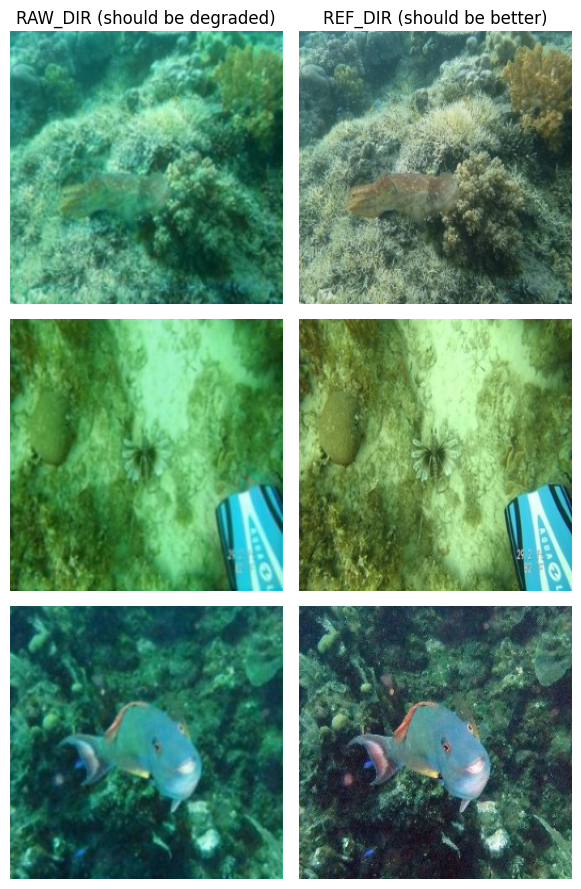

In [19]:
import random, shutil
from PIL import Image

# ------------------- EDIT HERE -------------------
# Paste the two folder paths printed by 4b (degraded folder, then its matching reference folder), e.g.
#   RAW_DIR = f"{KAGGLE_ROOT}/<...>/underwater_dark/trainA"
#   REF_DIR = f"{KAGGLE_ROOT}/<...>/underwater_dark/trainB"

EUVP = "/root/.cache/kagglehub/datasets/pamuduranasinghe/euvp-dataset/versions/1/EUVP"
RAW_DIR = f"{EUVP}/test_samples/Inp"   # degraded                                                                                                                                      │New file not yet
REF_DIR = f"{EUVP}/test_samples/GTr"   # reference     # matching reference images
N_IMAGES = 30
SEED = 1234
# -------------------------------------------------
assert RAW_DIR and REF_DIR, "Set RAW_DIR and REF_DIR above (use the paths printed by cell 4b)."
for d in (RAW_DIR, REF_DIR):
    assert os.path.isdir(d), f"not a folder: {d}"

SIZE = 256
OUT = "/content/euvp_test"
EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def index(d):
    return {os.path.splitext(f)[0]: os.path.join(d, f)
            for f in sorted(os.listdir(d)) if os.path.splitext(f)[1].lower() in EXT}

raw, ref = index(RAW_DIR), index(REF_DIR)
common = sorted(set(raw) & set(ref))
print(f"raw: {len(raw)}   ref: {len(ref)}   matched by filename: {len(common)}")
print(f"raw without ref: {len(set(raw) - set(ref))}   ref without raw: {len(set(ref) - set(raw))}")
if len(common) < N_IMAGES:
    print("example raw names:", sorted(raw)[:3])
    print("example ref names:", sorted(ref)[:3])
assert len(common) >= N_IMAGES, ("Not enough matched pairs. If the two example name lists above differ in style "
                                 "(different prefixes/suffixes), send them to me - the pairing rule needs adjusting.")

random.Random(SEED).shuffle(common)
picked = sorted(common[:N_IMAGES])

shutil.rmtree(OUT, ignore_errors=True)
for sub in ("input_256", "target_256"):
    os.makedirs(f"{OUT}/{sub}")
for i, stem in enumerate(picked):
    name = f"{i:04d}_{stem}.png"            # identical name in both folders -> sorted order pairs correctly
    Image.open(raw[stem]).convert("RGB").resize((SIZE, SIZE), Image.Resampling.LANCZOS).save(f"{OUT}/input_256/{name}")
    Image.open(ref[stem]).convert("RGB").resize((SIZE, SIZE), Image.Resampling.LANCZOS).save(f"{OUT}/target_256/{name}")
print("wrote", len(os.listdir(f"{OUT}/input_256")), "pairs to", OUT)

# quick visual check: left = RAW_DIR image (should be the degraded one), right = REF_DIR image (should look better)
import matplotlib.pyplot as plt
names = sorted(os.listdir(f"{OUT}/input_256"))[:3]
fig, ax = plt.subplots(len(names), 2, figsize=(6, 3 * len(names)), squeeze=False)
for r, nm in enumerate(names):
    for c, sub in enumerate(("input_256", "target_256")):
        ax[r][c].imshow(Image.open(f"{OUT}/{sub}/{nm}")); ax[r][c].axis("off")
ax[0][0].set_title("RAW_DIR (should be degraded)"); ax[0][1].set_title("REF_DIR (should be better)")
plt.tight_layout(); plt.show()

## Step 5 — Run-0 config and noise-schedule check
We take the repo's own `config/config.yml` and change only what Run 0 needs:

* `gpu_ids: [0]` (the original lists two GPUs, which would switch on `DataParallel`)
* `path.resume_state` → our checkpoint prefix
* the `val` dataset root → the folder from Step 4

Everything about the model (UNet size, 2000-step linear β schedule, 1e-6 → 1e-2) stays as the authors set it.

The second half checks the assignment's requirement for the native noise parameter. In this code the forward process is `x_t = √ᾱₜ x₀ + √(1−ᾱₜ) ε` with `ᾱₜ = ∏(1−βₛ)` (see `make_beta_schedule` and `set_new_noise_schedule` in `model/ddpm_modules/diffusion.py`), so **θₜ = ᾱₜ**, and we verify numerically that it lies in (0, 1).

In [17]:
import yaml, numpy as np

cfg = yaml.safe_load(open(f"{REPO_DIR}/config/config.yml"))
cfg["name"] = "Run0_EUVP"
cfg["gpu_ids"] = [0]
cfg["path"]["resume_state"] = CKPT_PREFIX
cfg["datasets"]["val"].update(dataroot=OUT, resolution=256, data_len=-1)

RUN0_CFG = f"{REPO_DIR}/config/run0.yml"
with open(RUN0_CFG, "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

# ---- schedule check (theta_t = alpha_bar_t) ----
bs = cfg["model"]["beta_schedule"]["val"]
assert bs["schedule"] == "linear", bs
betas = np.linspace(bs["linear_start"], bs["linear_end"], bs["n_timestep"], dtype=np.float64)
abar = np.cumprod(1.0 - betas)
print(f"T = {bs['n_timestep']},  beta in [{betas.min():.2e}, {betas.max():.2e}]")
print(f"alpha_bar_1 = {abar[0]:.8f}   alpha_bar_T = {abar[-1]:.3e}")
assert (betas > 0).all() and (betas < 1).all()
assert ((abar > 0) & (abar < 1)).all() and (np.diff(abar) < 0).all()
print("OK: alpha_bar_t is in (0,1) for every t and strictly decreasing")
print("UNet:", cfg["model"]["unet"])

T = 2000,  beta in [1.00e-06, 1.00e-02]
alpha_bar_1 = 0.99999900   alpha_bar_T = 4.386e-05
OK: alpha_bar_t is in (0,1) for every t and strictly decreasing
UNet: {'in_channel': 6, 'out_channel': 3, 'inner_channel': 64, 'norm_groups': 16, 'channel_multiplier': [1, 2, 4, 8, 16], 'attn_res': [], 'res_blocks': 1, 'dropout': 0, 'channels': 1024, 'ratio': 1, 'cond_in_dim': 3, 'image_size': 256}


## Step 6 — Dry run: load weights, count parameters, time one step
This loads the model exactly the way `test.py` does (`Model.create_model(opt)` → `load_network()` with `strict=True`). If the checkpoint doesn't match the architecture, **it fails here, in seconds**, instead of after a long run.

It then times one denoising-network forward pass and multiplies by 2000 to estimate seconds per image. Send me these numbers — they decide how many images we can afford.

In [18]:
import argparse, time, gc

os.chdir(REPO_DIR)
sys.path.insert(0, REPO_DIR)
import core.logger as Logger
import model as Model

args = argparse.Namespace(config="config/run0.yml", phase="val", gpu_ids="0", debug=False, enable_wandb=False)
opt = Logger.dict_to_nonedict(Logger.parse(args))
diffusion = Model.create_model(opt)                       # loads <prefix>_gen.pth (strict)
diffusion.set_new_noise_schedule(opt["model"]["beta_schedule"]["val"], schedule_phase="val")
print("checkpoint loaded OK")

net = diffusion.netG.eval()
print(f"parameters: {sum(p.numel() for p in net.parameters()) / 1e6:.1f} M")

x = torch.randn(1, 6, 256, 256, device="cuda")            # [condition(3) | noisy image(3)]
t = torch.full((1,), 1000, device="cuda", dtype=torch.long)
with torch.no_grad():
    for _ in range(3):
        net.denoise_fn(x, t)
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.time()
    for _ in range(10):
        net.denoise_fn(x, t)
    torch.cuda.synchronize()
per_step = (time.time() - t0) / 10
T = opt["model"]["beta_schedule"]["val"]["n_timestep"]
print(f"one denoising step : {per_step*1000:.1f} ms")
print(f"peak GPU memory    : {torch.cuda.max_memory_allocated()/1e9:.2f} GB")
print(f"=> ~{per_step*T:.0f} s per image ({T} steps); 100 images ~ {per_step*T*100/3600:.1f} h")

del diffusion, net, x, t
gc.collect(); torch.cuda.empty_cache()

export CUDA_VISIBLE_DEVICES=0
checkpoint loaded OK
parameters: 155.3 M
one denoising step : 137.3 ms
peak GPU memory    : 0.89 GB
=> ~275 s per image (2000 steps); 100 images ~ 7.6 h


In [24]:
import json
os.makedirs("/content/drive/MyDrive/FoundationModel-Assignment", exist_ok=True)
json.dump(picked, open("/content/drive/MyDrive/FoundationModel-Assignment/test_split_30.json", "w"))
print(len(picked), picked[:3])

30 ['test_p105_', 'test_p116_', 'test_p149_']


In [25]:
import threading, shutil, glob, time, os
SYNC_DST = "/content/drive/MyDrive/FoundationModel-Assignment/run0_diffwater_live"

def _sync():
    while True:
        for src in glob.glob(f"{REPO_DIR}/experiments/Run0_EUVP_*/results"):
            dst = f"{SYNC_DST}/{os.path.basename(os.path.dirname(src))}"
            os.makedirs(dst, exist_ok=True)
            for f in glob.glob(f"{src}/*.png"):
                d = f"{dst}/{os.path.basename(f)}"
                if not os.path.exists(d) and time.time() - os.path.getmtime(f) > 5:   # skip files still being written
                    shutil.copy(f, d)
        time.sleep(120)

threading.Thread(target=_sync, daemon=True).start()

## Step 7 — Run inference (Run 0)
We call the repo's own `test.py` (unmodified). It has **no random seed**, and the sampler starts from random noise, so two runs would give different images. To make Run 0 reproducible we launch it through a 6-line wrapper that seeds Python/NumPy/PyTorch and then runs `test.py` as-is. Record the seed in the README.

`test.py` writes, per image `k`, into `experiments/Run0_EUVP_<timestamp>/results/`:
`0_k_input.png` (colour-compensated input), `0_k_output.png` (**the model's result**), `0_k_target.png` (reference), `0_k_denoising_process.png` (intermediate steps).

In [26]:
RUN0_SEED = 1234

wrapper = '''import os, sys, random, runpy
import numpy as np, torch
seed = int(sys.argv.pop(1))
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
sys.path.insert(0, os.getcwd())
runpy.run_path("test.py", run_name="__main__")
'''
open("/content/run0_test.py", "w").write(wrapper)

t0 = time.time()
!cd {REPO_DIR} && python /content/run0_test.py {RUN0_SEED} -c config/run0.yml -gpu 0
print(f"\nelapsed: {(time.time()-t0)/60:.1f} min for {N_IMAGES} images")

export CUDA_VISIBLE_DEVICES=0
26-10-28 19:46:35.866 - INFO:   name: Run0_EUVP
  gpu_ids: [0]
  path:[
    log: experiments/Run0_EUVP_261028_194635/logs
    tb_logger: experiments/Run0_EUVP_261028_194635/tb_logger
    results: experiments/Run0_EUVP_261028_194635/results
    checkpoint: experiments/Run0_EUVP_261028_194635/checkpoint
    resume_state: /content/drive/MyDrive/DW/LSUI/I390000_E78
    experiments_root: experiments/Run0_EUVP_261028_194635
  ]
  datasets:[
    train:[
      name: UIEB
      dataroot: E:/UI-data/UIEB/train
      resolution: 256
      batch_size: 1
      num_workers: 8
      use_shuffle: True
      data_len: -1
    ]
    val:[
      name: UIEB
      dataroot: /content/euvp_test
      resolution: 256
      use_shuffle: True
      data_len: -1
    ]
  ]
  model:[
    unet:[
      in_channel: 6
      out_channel: 3
      inner_channel: 64
      norm_groups: 16
      channel_multiplier: [1, 2, 4, 8, 16]
      attn_res: []
      res_blocks: 1
      dropout: 0
      ch

## Step 8 — Evaluate and look at the results
DiffWater's own `eval.py` computes PSNR/SSIM between `*_input.png` and `*_target.png` (the *input*, not the output), so it does not measure the model. We compute our own with `scikit-image`: **output vs. reference** (Run 0), and **raw input vs. reference** as a "do-nothing" baseline for context.

A sanity check also confirms the target the model saw is byte-identical to the reference file we prepared, i.e. the pairing is intact.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import glob, os, numpy as np, pandas as pd
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

exp = "/content/drive/MyDrive/FoundationModel-Assignment/run0_diffwater_live/Run0_EUVP_261028_194635"
idxs = sorted({int(os.path.basename(p).split("_")[1]) for p in glob.glob(f"{exp}/0_*_output.png")})
need = ["input", "output", "target", "denoising_process"]
complete = [i for i in idxs if all(os.path.exists(f"{exp}/0_{i}_{k}.png") for k in need)]
print("images with all 4 files:", len(complete), "of 30; missing:", sorted(set(range(1, 31)) - set(complete)))

load = lambda i, k: np.array(Image.open(f"{exp}/0_{i}_{k}.png").convert("RGB"))
rows = []
for i in complete:
    out, tgt, inp = load(i, "output"), load(i, "target"), load(i, "input")
    rows.append(dict(idx=i,
        psnr_out=psnr(tgt, out, data_range=255), ssim_out=ssim(tgt, out, channel_axis=2, data_range=255),
        psnr_in=psnr(tgt, inp, data_range=255),  ssim_in=ssim(tgt, inp, channel_axis=2, data_range=255)))
df = pd.DataFrame(rows)
df.to_csv("/content/drive/MyDrive/FoundationModel-Assignment/run0_metrics_from_drive.csv", index=False)
print(df.round(3).to_string(index=False))
print(df[["psnr_out", "ssim_out", "psnr_in", "ssim_in"]].agg(["mean", "std"]).round(3))

Mounted at /content/drive
images with all 4 files: 30 of 30; missing: []
 idx  psnr_out  ssim_out  psnr_in  ssim_in
   1    17.781     0.775   19.899    0.784
   2    17.921     0.837   17.584    0.830
   3    17.124     0.733   22.287    0.772
   4    20.994     0.783   22.501    0.847
   5    15.217     0.739   22.006    0.881
   6    19.784     0.717   11.736    0.611
   7    17.661     0.768   23.528    0.794
   8    15.581     0.655   19.619    0.778
   9    15.033     0.692   23.443    0.839
  10    19.524     0.728   19.059    0.722
  11    23.320     0.844   19.127    0.880
  12    19.633     0.832   24.419    0.856
  13    18.511     0.778   18.767    0.878
  14    20.718     0.786   22.326    0.776
  15    23.640     0.793   14.835    0.769
  16    16.788     0.743   23.019    0.789
  17    17.210     0.720   24.254    0.859
  18    16.055     0.748   23.363    0.820
  19    11.419     0.690   12.027    0.691
  20    18.581     0.783   22.139    0.801
  21    20.369     0.692

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn

runs = sorted(glob.glob(f"{REPO_DIR}/experiments/Run0_EUVP_*/results"), key=os.path.getmtime)
runs = [r for r in runs if glob.glob(f"{r}/*_output.png")]
assert runs, "No outputs found - scroll up in Step 7 for the error."
RES = runs[-1]
print("results dir:", RES)

load = lambda p: np.array(Image.open(p).convert("RGB"))
raw_files = sorted(glob.glob(f"{OUT}/input_256/*.png"))
rows = []
for k, rf in enumerate(raw_files, start=1):
    out, tgt = load(f"{RES}/0_{k}_output.png"), load(f"{RES}/0_{k}_target.png")
    ref_file = load(rf.replace("input_256", "target_256"))
    assert np.abs(tgt.astype(int) - ref_file.astype(int)).max() <= 1, f"pair mismatch at image {k}"
    raw_img = load(rf)
    rows.append(dict(idx=k, name=os.path.basename(rf),
                     psnr_run0=psnr_fn(tgt, out, data_range=255),
                     ssim_run0=ssim_fn(tgt, out, data_range=255, channel_axis=2),
                     psnr_raw=psnr_fn(tgt, raw_img, data_range=255),
                     ssim_raw=ssim_fn(tgt, raw_img, data_range=255, channel_axis=2)))
df = pd.DataFrame(rows)
df.to_csv("/content/run0_metrics.csv", index=False)
display(df.round(4))
print(df[["psnr_run0", "ssim_run0", "psnr_raw", "ssim_raw"]].mean().round(4).to_string())

n_show = min(6, len(df))
fig, ax = plt.subplots(n_show, 4, figsize=(12, 3 * n_show), squeeze=False)
for k in range(1, n_show + 1):
    imgs = [load(raw_files[k-1]), load(f"{RES}/0_{k}_input.png"), load(f"{RES}/0_{k}_output.png"), load(f"{RES}/0_{k}_target.png")]
    for j, (im, title) in enumerate(zip(imgs, ["raw input", "colour-compensated input", "Run 0 output", "reference"])):
        ax[k-1][j].imshow(im); ax[k-1][j].axis("off")
        if k == 1: ax[0][j].set_title(title)
plt.tight_layout(); plt.show()

plt.figure(figsize=(14, 3)); plt.imshow(load(f"{RES}/0_1_denoising_process.png")); plt.axis("off")
plt.title("image 1: intermediate reverse-diffusion steps"); plt.show()

## Step 9 — Save to Drive
Colab's disk is wiped when the session ends. This zips the Run-0 outputs, the metrics CSV, and the exact config used, and copies the zip to your Drive.

In [ ]:
SAVE_DIR = "/content/drive/MyDrive/FoundationModel-Assignment/run0_diffwater"
os.makedirs(SAVE_DIR, exist_ok=True)
shutil.copy(RUN0_CFG, RES)                                   # keep the exact config next to the outputs
shutil.copy("/content/run0_metrics.csv", RES)
zip_path = shutil.make_archive(f"{SAVE_DIR}/run0_outputs_seed{RUN0_SEED}_n{N_IMAGES}", "zip", RES)
print("saved:", zip_path)

## What to send back
Paste (or screenshot) these and I'll check them and plan Runs A/B:

1. The file listing printed in **Step 3a/3c** and which checkpoint was chosen.
2. **Step 6** output: parameter count, ms per step, peak GPU memory, estimated seconds per image.
3. The **Step 8** table + mean PSNR/SSIM, and the image grid.
4. Any error text, from the first red line.

## Caveats
* I wrote this notebook against the code in the repo but **could not run it on a GPU**, so Step 6 exists to catch problems cheaply.
* PSNR/SSIM on a handful of images is only a smoke test, not a result.
* Run 0 uses full 2000-step sampling as the authors' code does. If we later need fewer steps (for speed), we must use the same setting for Run 0, A and B.